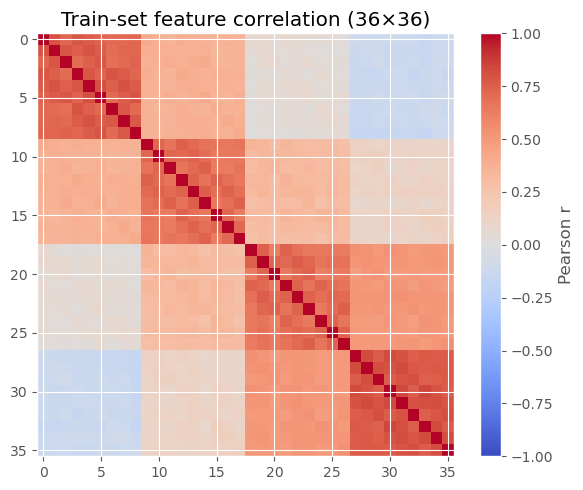

Using two original features for 2D plots: V31, V32


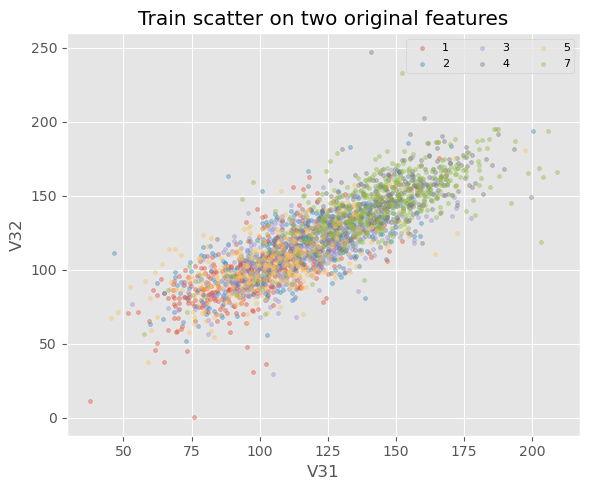

/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi


=== 5-fold CV (train split) ===
Logistic: macro-F1 0.609 ± 0.012, acc 0.610
LDA:      macro-F1 0.628 ± 0.022, acc 0.630


/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



=== Held-out test set ===
  Logistic — Test acc: 0.615 | Test macro-F1: 0.614
       LDA — Test acc: 0.630 | Test macro-F1: 0.627


/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


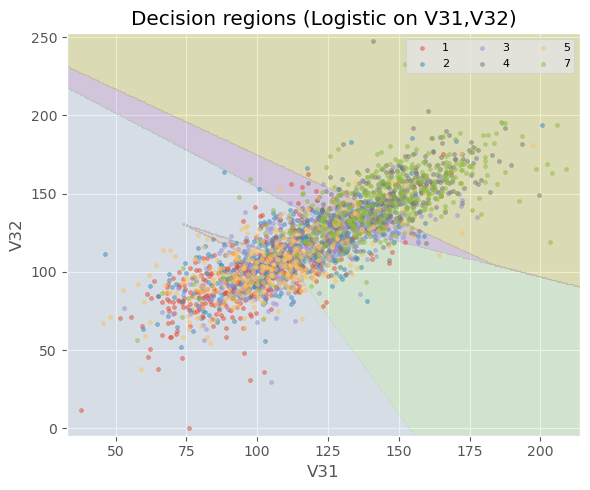

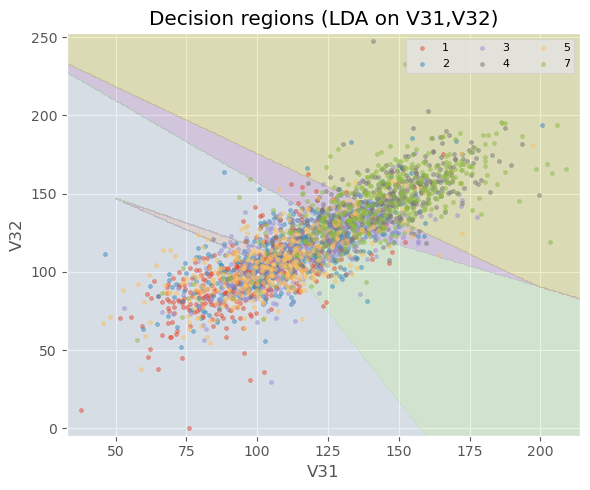

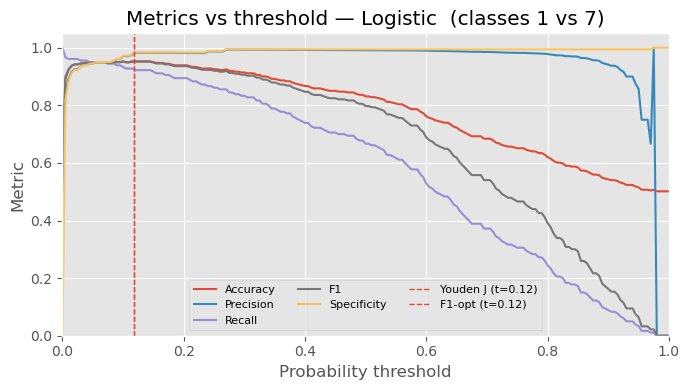

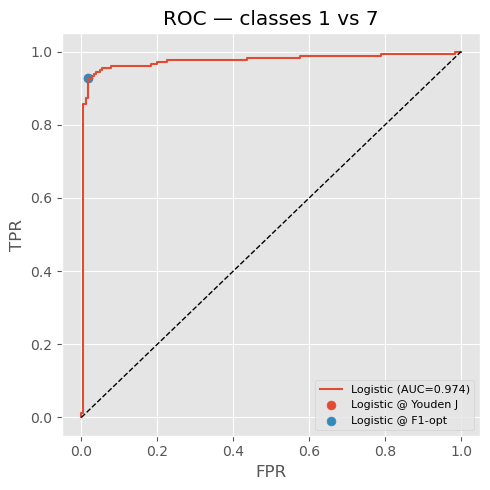

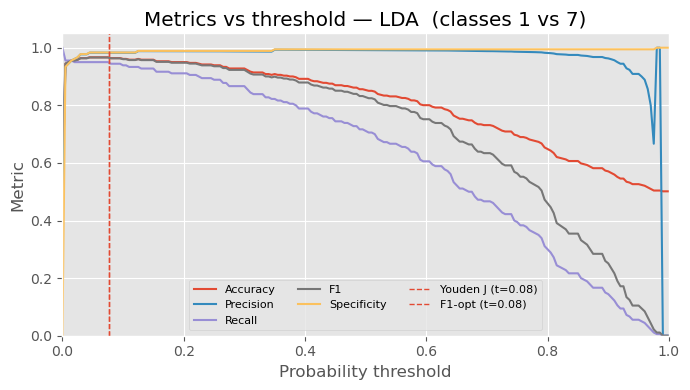

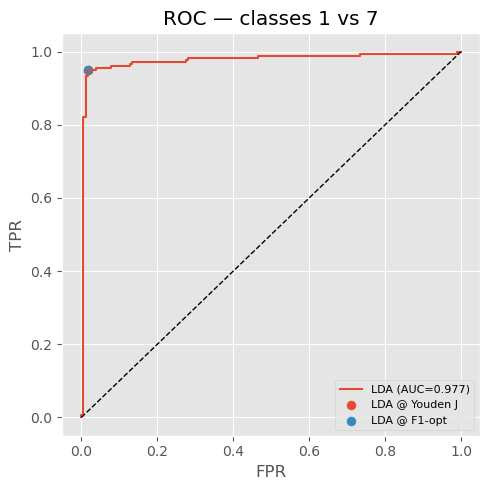

Logistic @ Youden J t=0.117 | Acc 0.956  Prec 0.982  Rec 0.928  F1 0.954  Spec 0.983
Logistic @ F1-opt   t=0.117 | Acc 0.956  Prec 0.982  Rec 0.928  F1 0.954  Spec 0.983
     LDA @ Youden J t=0.077 | Acc 0.967  Prec 0.983  Rec 0.950  F1 0.966  Spec 0.983
     LDA @ F1-opt   t=0.077 | Acc 0.967  Prec 0.983  Rec 0.950  F1 0.966  Spec 0.983


In [4]:
# =============================================================
#  Noisy Landsat-like dataset (36 features) + visuals (no PCA)
#  -------------------------------------------------------------
#  * 36 raw features (3×3 pixels × 4 bands), labels {1,2,3,4,5,7}
#  * Visuals: correlation heatmap + 2D scatter using ORIGINAL features
#  * Multiclass Logistic vs LDA: 5-fold CV macro-F1/accuracy + test set
#  * 2D decision regions on chosen two original features
#  * Binary subproblem: metrics vs threshold + ROC/AUC (Youden J, F1-opt)
# =============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("ggplot")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, roc_auc_score
)

# ---------------- 1) Noisy synthetic generator -----------------------------
def make_landsat_like(n_per_class=600, seed=7,
                      sep=0.6,        # <1 shrinks inter-class mean separation
                      cov_scale=80.0, # larger => more within-class spread
                      cross_rho=0.30, # cross-band correlation
                      glob_sigma=12.0,# per-patch global illumination jitter
                      band_sigma=8.0, # per-band offset jitter
                      t_scale=6.0,    # heavy-tailed pixel noise (t df=3)
                      label_flip=0.06 # fraction of labels randomly flipped
                      ):
    rng = np.random.default_rng(seed)
    classes = [1, 2, 3, 4, 5, 7]
    base_band_means = {
        1: [150, 100,  90,  80],
        2: [120, 140, 110, 100],
        3: [100, 120, 130, 110],
        4: [ 90, 110, 140, 150],
        5: [130, 130, 100,  90],
        7: [ 80,  90, 120, 160],
    }
    shrink = lambda m: 128 + sep * (np.array(m) - 128)

    # Spatial 3×3 covariance and cross-band coupling => 36×36 covariance
    coords = np.array([(i, j) for i in range(3) for j in range(3)])
    D = ((coords[:, None, :] - coords[None, :, :])**2).sum(axis=2)
    base_cov = np.exp(-D / (2 * 1.0**2))
    Sigma = np.zeros((36, 36))
    for bi in range(4):
        for bj in range(4):
            block = base_cov if bi == bj else cross_rho * base_cov
            Sigma[bi*9:(bi+1)*9, bj*9:(bj+1)*9] = block
    Sigma *= cov_scale

    X_list, y_list = [], []
    for c in classes:
        mu_bands = shrink(base_band_means[c])
        mu_patch = np.concatenate([np.full(9, m) for m in mu_bands])
        Xc = rng.multivariate_normal(mu_patch, Sigma, size=n_per_class)

        # Global + per-band illumination jitter
        glob = rng.normal(0, glob_sigma, size=(n_per_class, 1))
        band = rng.normal(0, band_sigma, size=(n_per_class, 4))
        band_expanded = np.hstack([np.repeat(band[:, [k]], 9, axis=1) for k in range(4)])
        Xc = Xc + glob + band_expanded

        # Heavy-tailed pixel noise
        Xc = Xc + rng.standard_t(df=3, size=Xc.shape) * t_scale

        X_list.append(Xc)
        y_list.append(np.full(n_per_class, c))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)

    # Optional label noise
    if label_flip > 0:
        idx = rng.choice(len(y), size=int(label_flip * len(y)), replace=False)
        for i in idx:
            y[i] = rng.choice([cl for cl in classes if cl != y[i]])

    X = np.clip(X, 0, 255)
    cols = [f"V{j+1}" for j in range(36)]
    return pd.DataFrame(X, columns=cols), pd.Series(y, name="label")

# Generate data
X, y = make_landsat_like()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# ---------------- 2) Visualizations (NO PCA) -------------------------------
# 2a) Correlation heatmap on train set
corr = X_tr.corr()
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.title("Train-set feature correlation (36×36)")
plt.colorbar(label="Pearson r")
plt.tight_layout()
plt.show()

# 2b) Choose two ORIGINAL features for plotting:
#     pick top-2 by ANOVA F-score (still original axes, just a data-driven choice)
F, _ = f_classif(X_tr, y_tr)
top2_idx = np.argsort(F)[-2:]
feat_x, feat_y = X_tr.columns[top2_idx[0]], X_tr.columns[top2_idx[1]]
print(f"Using two original features for 2D plots: {feat_x}, {feat_y}")

plt.figure(figsize=(6, 5))
for cls in np.unique(y_tr):
    m = y_tr == cls
    plt.scatter(X_tr.loc[m, feat_x], X_tr.loc[m, feat_y], s=8, alpha=0.4, label=str(cls))
plt.xlabel(feat_x); plt.ylabel(feat_y)
plt.title("Train scatter on two original features")
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# ---------------- 3) Multiclass Logistic vs LDA (5-fold CV) ----------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe_lr  = Pipeline([("sc", StandardScaler()),
                     ("clf", LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=500))])
pipe_lda = Pipeline([("sc", StandardScaler()), ("clf", LDA())])

scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy"}
res_lr  = cross_validate(pipe_lr,  X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)
res_lda = cross_validate(pipe_lda, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)

print("\n=== 5-fold CV (train split) ===")
print(f"Logistic: macro-F1 {res_lr['test_f1_macro'].mean():.3f} ± {res_lr['test_f1_macro'].std():.3f}, "
      f"acc {res_lr['test_accuracy'].mean():.3f}")
print(f"LDA:      macro-F1 {res_lda['test_f1_macro'].mean():.3f} ± {res_lda['test_f1_macro'].std():.3f}, "
      f"acc {res_lda['test_accuracy'].mean():.3f}")

# Fit on full train, evaluate on held-out test
pipe_lr.fit(X_tr, y_tr);  yhat_lr  = pipe_lr.predict(X_te)
pipe_lda.fit(X_tr, y_tr); yhat_lda = pipe_lda.predict(X_te)

def summarize_test(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    print(f"{name:>10s} — Test acc: {acc:.3f} | Test macro-F1: {f1m:.3f}")

print("\n=== Held-out test set ===")
summarize_test(y_te, yhat_lr,  "Logistic")
summarize_test(y_te, yhat_lda, "LDA")

# ---------------- 4) 2D decision regions (on the two original features) ----
def plot_decision_regions_2d(model, X_df, y_ser, f1, f2, title):
    X2 = X_df[[f1, f2]].copy()
    pipe2 = Pipeline([("sc", StandardScaler()), ( "clf", model.__class__(**model.get_params()) )])
    pipe2.fit(X2, y_ser)

    # mesh
    x_min, x_max = X2[f1].min()-5, X2[f1].max()+5
    y_min, y_max = X2[f2].min()-5, X2[f2].max()+5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
    Z = pipe2.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(6,5))
    plt.contourf(xx, yy, Z, alpha=0.25, levels=np.unique(y_ser), cmap="tab20")
    for cls in np.unique(y_ser):
        m = y_ser == cls
        plt.scatter(X2.loc[m, f1], X2.loc[m, f2], s=8, alpha=0.5, label=str(cls))
    plt.xlabel(f1); plt.ylabel(f2)
    plt.title(title)
    plt.legend(ncol=3, fontsize=8)
    plt.tight_layout()
    plt.show()

plot_decision_regions_2d(pipe_lr.named_steps["clf"],  X_tr, y_tr, feat_x, feat_y,
                         f"Decision regions (Logistic on {feat_x},{feat_y})")
plot_decision_regions_2d(pipe_lda.named_steps["clf"], X_tr, y_tr, feat_x, feat_y,
                         f"Decision regions (LDA on {feat_x},{feat_y})")

# ---------------- 5) Binary subproblem: thresholds + ROC/AUC ----------------
pair = (1, 7)  # example: choose two classes to compare
mask_te = y_te.isin(pair)
X_bin, y_bin = X_te[mask_te], y_te[mask_te]
y_bin01 = (y_bin == pair[1]).astype(int)

# Scores from multiclass models restricted to these two classes
def prob_for_class(pipe, X_subset, positive_label):
    classes = list(pipe.named_steps["clf"].classes_)
    p = pipe.predict_proba(X_subset)[:, classes.index(positive_label)]
    return p

proba_lr  = prob_for_class(pipe_lr,  X_bin, pair[1])
proba_lda = prob_for_class(pipe_lda, X_bin, pair[1])

def metrics_at_threshold(y_true01, score, thresh):
    yhat = (score >= thresh).astype(int)
    acc = accuracy_score(y_true01, yhat)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true01, yhat, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true01, yhat).ravel()
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    return acc, prec, rec, f1, spec

def find_thresholds(y_true01, score):
    fpr, tpr, thr = roc_curve(y_true01, score)
    j_vals = tpr - fpr
    t_j = thr[np.argmax(j_vals)]
    uniq = np.unique(score)
    f1s = [metrics_at_threshold(y_true01, score, t)[3] for t in uniq]
    t_f1 = uniq[int(np.argmax(f1s))]
    return float(t_j), float(t_f1), (fpr, tpr, thr)

def plot_metrics_vs_threshold(y_true01, score, label):
    ts = np.linspace(0, 1, 201)
    accs, precs, recs, f1s, specs = [], [], [], [], []
    for t in ts:
        acc, prec, rec, f1, spec = metrics_at_threshold(y_true01, score, t)
        accs.append(acc); precs.append(prec); recs.append(rec); f1s.append(f1); specs.append(spec)
    t_j, t_f1, _ = find_thresholds(y_true01, score)

    plt.figure(figsize=(7, 4))
    plt.plot(ts, accs, label="Accuracy")
    plt.plot(ts, precs, label="Precision")
    plt.plot(ts, recs, label="Recall")
    plt.plot(ts, f1s, label="F1")
    plt.plot(ts, specs, label="Specificity")
    for t, nm in [(t_j, "Youden J"), (t_f1, "F1-opt")]:
        plt.axvline(t, linestyle="--", linewidth=1, label=f"{nm} (t={t:.2f})")
    plt.ylim(0, 1.05); plt.xlim(0, 1)
    plt.xlabel("Probability threshold"); plt.ylabel("Metric")
    plt.title(f"Metrics vs threshold — {label}  (classes {pair[0]} vs {pair[1]})")
    plt.legend(ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()
    return t_j, t_f1

def plot_roc(y_true01, score, label, t_marks):
    fpr, tpr, thr = roc_curve(y_true01, score)
    auc = roc_auc_score(y_true01, score)
    plt.figure(figsize=(5, 5))
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    for t, nm in t_marks:
        idx = np.argmin(np.abs(thr - t))
        plt.scatter(fpr[idx], tpr[idx], s=40, label=f"{label} @ {nm}")
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.title(f"ROC — classes {pair[0]} vs {pair[1]}")
    plt.legend(fontsize=8)
    plt.tight_layout(); plt.show()

# Logistic
tJ_lr, tF_lr = plot_metrics_vs_threshold(y_bin01, proba_lr,  "Logistic")
plot_roc(y_bin01, proba_lr, "Logistic", [(tJ_lr, "Youden J"), (tF_lr, "F1-opt")])

# LDA
tJ_ld, tF_ld = plot_metrics_vs_threshold(y_bin01, proba_lda, "LDA")
plot_roc(y_bin01, proba_lda, "LDA", [(tJ_ld, "Youden J"), (tF_ld, "F1-opt")])

# Print metric tables at selected thresholds
for name, score, tJ, tF in [
    ("Logistic", proba_lr,  tJ_lr, tF_lr),
    ("LDA",      proba_lda, tJ_ld, tF_ld),
]:
    for t, tag in [(tJ, "Youden J"), (tF, "F1-opt")]:
        acc, prec, rec, f1, spec = metrics_at_threshold(y_bin01, score, t)
        print(f"{name:>8s} @ {tag:8s} t={t:.3f} | Acc {acc:.3f}  Prec {prec:.3f}  Rec {rec:.3f}  F1 {f1:.3f}  Spec {spec:.3f}")
